# tiler tutorial

This notebook walks through everything `tiler` does, bottom-up: the lattice math,
the group symmetry operations, **how the true fundamental domain of a wallpaper
group is constructed** (the part you're probably most interested in), the
`FundamentalDomain`/`ImagePlacement` object model, how a covering of the plane is
rendered from it, and finally a guided tour of every control in the interactive
`TilerWidget`.

In [1]:
import io

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from PIL import Image as PILImage
from IPython.display import SVG, display

from tiler.lattice import LatticeKind, basis_vectors, lattice_translations
from tiler.groups import GROUP_SYMBOLS, WALLPAPER_GROUPS, coset_representatives
from tiler.fundamental_domain import dirichlet_domain, default_base_point, polygon_area
from tiler.domain import FundamentalDomain
from tiler.render import covering_transforms, generate_covering, svg_from_paths

plt.rcParams["figure.figsize"] = (5, 5)

## 1. The five 2D Bravais lattices

Every wallpaper group's translations form a 2D lattice: all integer combinations
`m*a1 + n*a2` of two basis vectors `a1`, `a2`. There are only five essentially
different lattice *shapes* -- `tiler.lattice.LatticeKind` enumerates them, and
`basis_vectors()` builds `a1, a2` for a given cell size / axis ratio / angle
(ratio and angle only matter for the lattice kinds that aren't rigid).

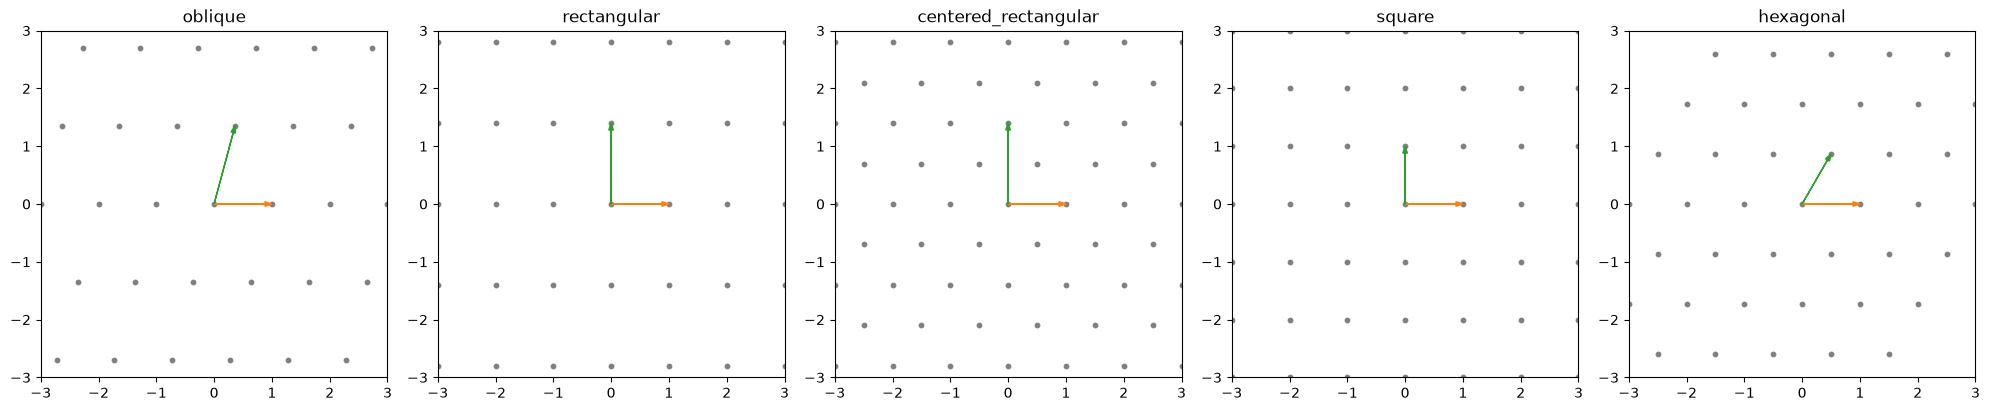

In [2]:
kinds = [
    LatticeKind.OBLIQUE,
    LatticeKind.RECTANGULAR,
    LatticeKind.CENTERED_RECTANGULAR,
    LatticeKind.SQUARE,
    LatticeKind.HEXAGONAL,
]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, kind in zip(axes, kinds):
    a1, a2 = basis_vectors(kind, cell_size=1.0, ratio=1.4, angle_deg=75.0)
    pts = np.array(list(lattice_translations(kind, a1, a2, range(-3, 4), range(-3, 4))))
    ax.scatter(pts[:, 0], pts[:, 1], s=10, c="0.5")
    ax.arrow(0, 0, *a1, color="C1", head_width=0.08, length_includes_head=True)
    ax.arrow(0, 0, *a2, color="C2", head_width=0.08, length_includes_head=True)
    ax.set_title(kind.value)
    ax.set_aspect("equal")
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
plt.tight_layout()
plt.show()

Note the *centered rectangular* lattice: it looks rectangular but has an extra
point at the center of every cell (that's what "centered" means, and it's why `cm`
and `cmm` need a `centering_offsets()` on top of the integer translations -- see
`tiler.lattice.centering_offsets`).

## 2. The 17 wallpaper groups and their point-group operations

A wallpaper group is a lattice type plus a finite set of **coset representatives**:
rotations, reflections, and glide reflections that, combined with the lattice
translations, generate the whole (infinite) group. `coset_representatives(symbol,
a1, a2)` returns them as `Affine2D` transforms (`p -> matrix @ p + translation`) in
Cartesian coordinates.

In [3]:
print(f"{'symbol':7s} {'orbifold':9s} {'lattice':22s} order")
for s in GROUP_SYMBOLS:
    g = WALLPAPER_GROUPS[s]
    print(f"{s:7s} {g.orbifold:9s} {g.lattice_kind.value:22s} {len(g.frac_ops)}")

symbol  orbifold  lattice                order
p1      o         oblique                1
p2      2222      oblique                2
pm      **        rectangular            2
pg      xx        rectangular            2
cm      *x        centered_rectangular   2
pmm     *2222     rectangular            4
pmg     22*       rectangular            4
pgg     22x       rectangular            4
cmm     2*22      centered_rectangular   4
p4      442       square                 4
p4m     *442      square                 8
p4g     4*2       square                 8
p3      333       hexagonal              3
p3m1    *333      hexagonal              6
p31m    3*3       hexagonal              6
p6      632       hexagonal              6
p6m     *632      hexagonal              12


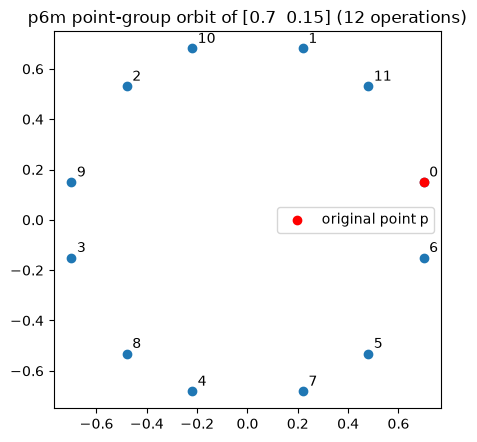

In [4]:
# Apply every coset representative of p6m to one point, to see the point-group orbit
# (12 operations: 6 rotations x {identity, mirror}).
a1, a2 = basis_vectors(WALLPAPER_GROUPS["p6m"].lattice_kind)
reps = coset_representatives("p6m", a1, a2)
p = np.array([0.7, 0.15])
orbit_within_cell = np.array([rep.apply(p.reshape(1, 2))[0] for rep in reps])

fig, ax = plt.subplots()
ax.scatter(*orbit_within_cell.T, c="C0", zorder=3)
for i, (x, y) in enumerate(orbit_within_cell):
    ax.annotate(str(i), (x, y), textcoords="offset points", xytext=(4, 4))
ax.scatter(*p, c="red", zorder=5, label="original point p")
ax.set_aspect("equal")
ax.legend()
ax.set_title(f"p6m point-group orbit of {p} ({len(reps)} operations)")
plt.show()

## 3. Constructing the fundamental domain

The parallelogram *unit cell* is a fundamental domain for the **translation**
subgroup only: tile the plane with copies of it shifted by lattice vectors and
nothing overlaps or is missed. But it is *not* a fundamental domain for the full
wallpaper group, which also has rotations/reflections/glides -- a cell-sized motif
would be duplicated (once per point-group operation) instead of appearing once per
copy.

Deriving the *true* fundamental domain by hand is a genuinely different, fiddly
shape for each of the 17 groups (a rectangle for `pmm`, a triangle for `p4m`, a
different triangle for `p6m`, a hexagon for `p1`, ...). Instead of hand-deriving 17
shapes, `tiler` uses a **Dirichlet domain** (a Voronoi cell), which is completely
general:

1. Pick a generic point `p` -- one that doesn't happen to sit on a mirror line or
   rotation center (`tiler.fundamental_domain.default_base_point` picks an
   irrational-ish fractional coordinate that avoids every group's special points).
2. Compute the **orbit** of `p`: every image `g * p` for `g` in the group (every
   coset representative composed with every nearby lattice translation).
3. Define the domain as every point closer to `p` than to any of its orbit images:

   `D = { x : |x - p| <= |x - g*p|  for every  g != identity }`

Each single condition `|x - p| <= |x - q|` is a half-plane (the side of the
perpendicular bisector of `p` and `q` that contains `p`). Intersecting all of
them -- clipping a big square down, one bisector at a time -- gives a convex
polygon: the fundamental domain. Because this argument never mentions *which*
group it is, the exact same few lines of code work for all 17.

Let's build one by hand, step by step, for `p4g` (4-fold rotations, but the
mirrors are glides, not passing through the rotation centers -- one of the more
interesting shapes).

In [5]:
def clip_by_bisector(polygon, midpoint, normal):
    """Keep the part of a convex polygon on p's side of the bisector of (p, q)."""
    out = []
    n = len(polygon)
    for i in range(n):
        cur, nxt = polygon[i], polygon[(i + 1) % n]
        cur_in = np.dot(cur - midpoint, normal) <= 1e-9
        nxt_in = np.dot(nxt - midpoint, normal) <= 1e-9
        if cur_in:
            out.append(cur)
        if cur_in != nxt_in:
            t = np.dot(midpoint - cur, normal) / np.dot(nxt - cur, normal)
            out.append(cur + t * (nxt - cur))
    return out


symbol = "p4g"
kind = WALLPAPER_GROUPS[symbol].lattice_kind
a1, a2 = basis_vectors(kind)
base_point = default_base_point(a1, a2)
reps = coset_representatives(symbol, a1, a2)
translations = list(lattice_translations(kind, a1, a2, range(-2, 3), range(-2, 3)))

# the orbit of base_point: every (rotation/reflection) x (lattice translation)
orbit = np.array([rep.apply(base_point.reshape(1, 2))[0] + t for rep in reps for t in translations])
orbit = orbit[np.linalg.norm(orbit - base_point, axis=1) > 1e-9]  # drop base_point itself
orbit = orbit[np.argsort(np.linalg.norm(orbit - base_point, axis=1))]  # nearest first

print(f"{len(reps)} point-group operations x {len(translations)} nearby lattice translations")
print(f"-> {len(orbit)} orbit points to clip against")

8 point-group operations x 25 nearby lattice translations
-> 199 orbit points to clip against


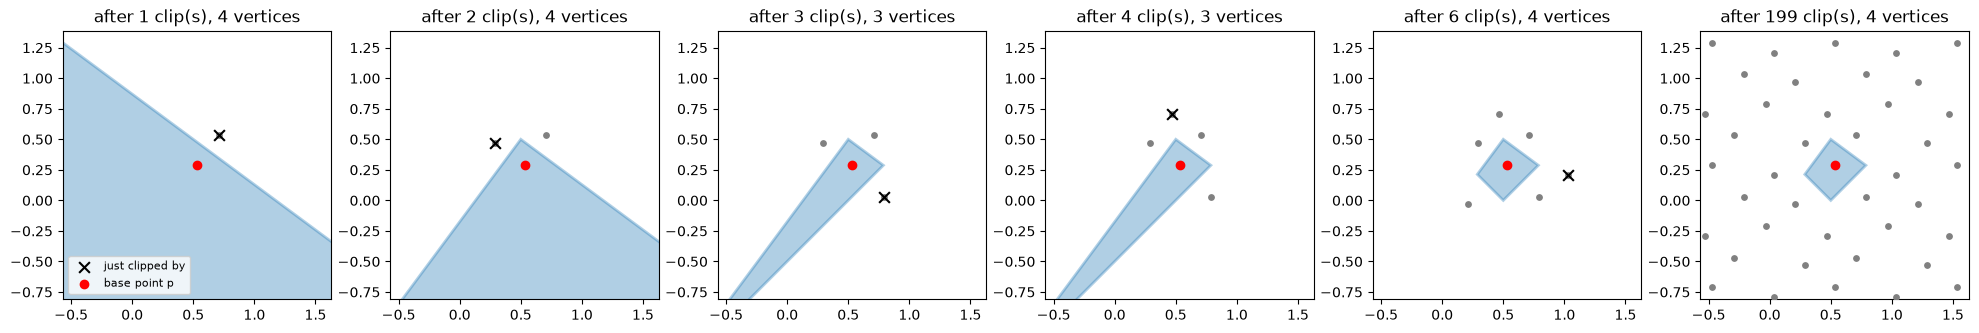

final domain: 4 vertices, area 0.1250


In [6]:
# start from a big square around base_point, then clip by the nearest orbit points
span = 6 * max(np.linalg.norm(a1), np.linalg.norm(a2))
polygon = [
    base_point + np.array([-span, -span]),
    base_point + np.array([span, -span]),
    base_point + np.array([span, span]),
    base_point + np.array([-span, span]),
]

steps_to_show = [0, 1, 2, 3, 5, len(orbit) - 1]
fig, axes = plt.subplots(1, len(steps_to_show), figsize=(3.3 * len(steps_to_show), 3.3))
shown = 0
for i, q in enumerate(orbit):
    midpoint = (base_point + q) / 2
    normal = q - base_point
    polygon = clip_by_bisector(polygon, midpoint, normal)
    if i in steps_to_show:
        ax = axes[shown]
        shown += 1
        ax.add_patch(MplPolygon(np.array(polygon), closed=True, fc="C0", alpha=0.35, ec="C0", lw=2))
        ax.scatter(*orbit[: i + 1].T, c="0.5", s=15, zorder=3)
        ax.scatter(*q, c="black", marker="x", s=60, zorder=4, label="just clipped by")
        ax.scatter(*base_point, c="red", zorder=5, label="base point p")
        ax.set_xlim(base_point[0] - 1.1, base_point[0] + 1.1)
        ax.set_ylim(base_point[1] - 1.1, base_point[1] + 1.1)
        ax.set_aspect("equal")
        ax.set_title(f"after {i + 1} clip(s), {len(polygon)} vertices")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

print(f"final domain: {len(polygon)} vertices, area {polygon_area(np.array(polygon)):.4f}")

Most of the ~200 candidate bisectors turn out to be redundant (the domain is
already inside their half-plane before we even get to them) -- only the handful of
*nearest* orbit points actually cut off a piece. This is exactly what
`tiler.fundamental_domain.dirichlet_domain()` does (same algorithm, same default
base point); let's confirm it gives the same result:

In [7]:
official = dirichlet_domain(symbol, a1, a2)
mine = np.array(polygon)
print(f"library:        {len(official)} vertices, area {polygon_area(official):.6f}")
print(f"step-by-step:   {len(mine)} vertices, area {polygon_area(mine):.6f}")
print(f"identical vertices: {np.allclose(official, mine)}")

library:        4 vertices, area 0.125000
step-by-step:   4 vertices, area 0.125000
identical vertices: True


### Gallery: the fundamental domain of every wallpaper group

Same one-liner (`dirichlet_domain(symbol, a1, a2)`), no per-group special-casing.
Notice how the shape gets smaller and more constrained as the point-group order
goes up (more symmetry -> more, tighter-fitting copies per unit cell).

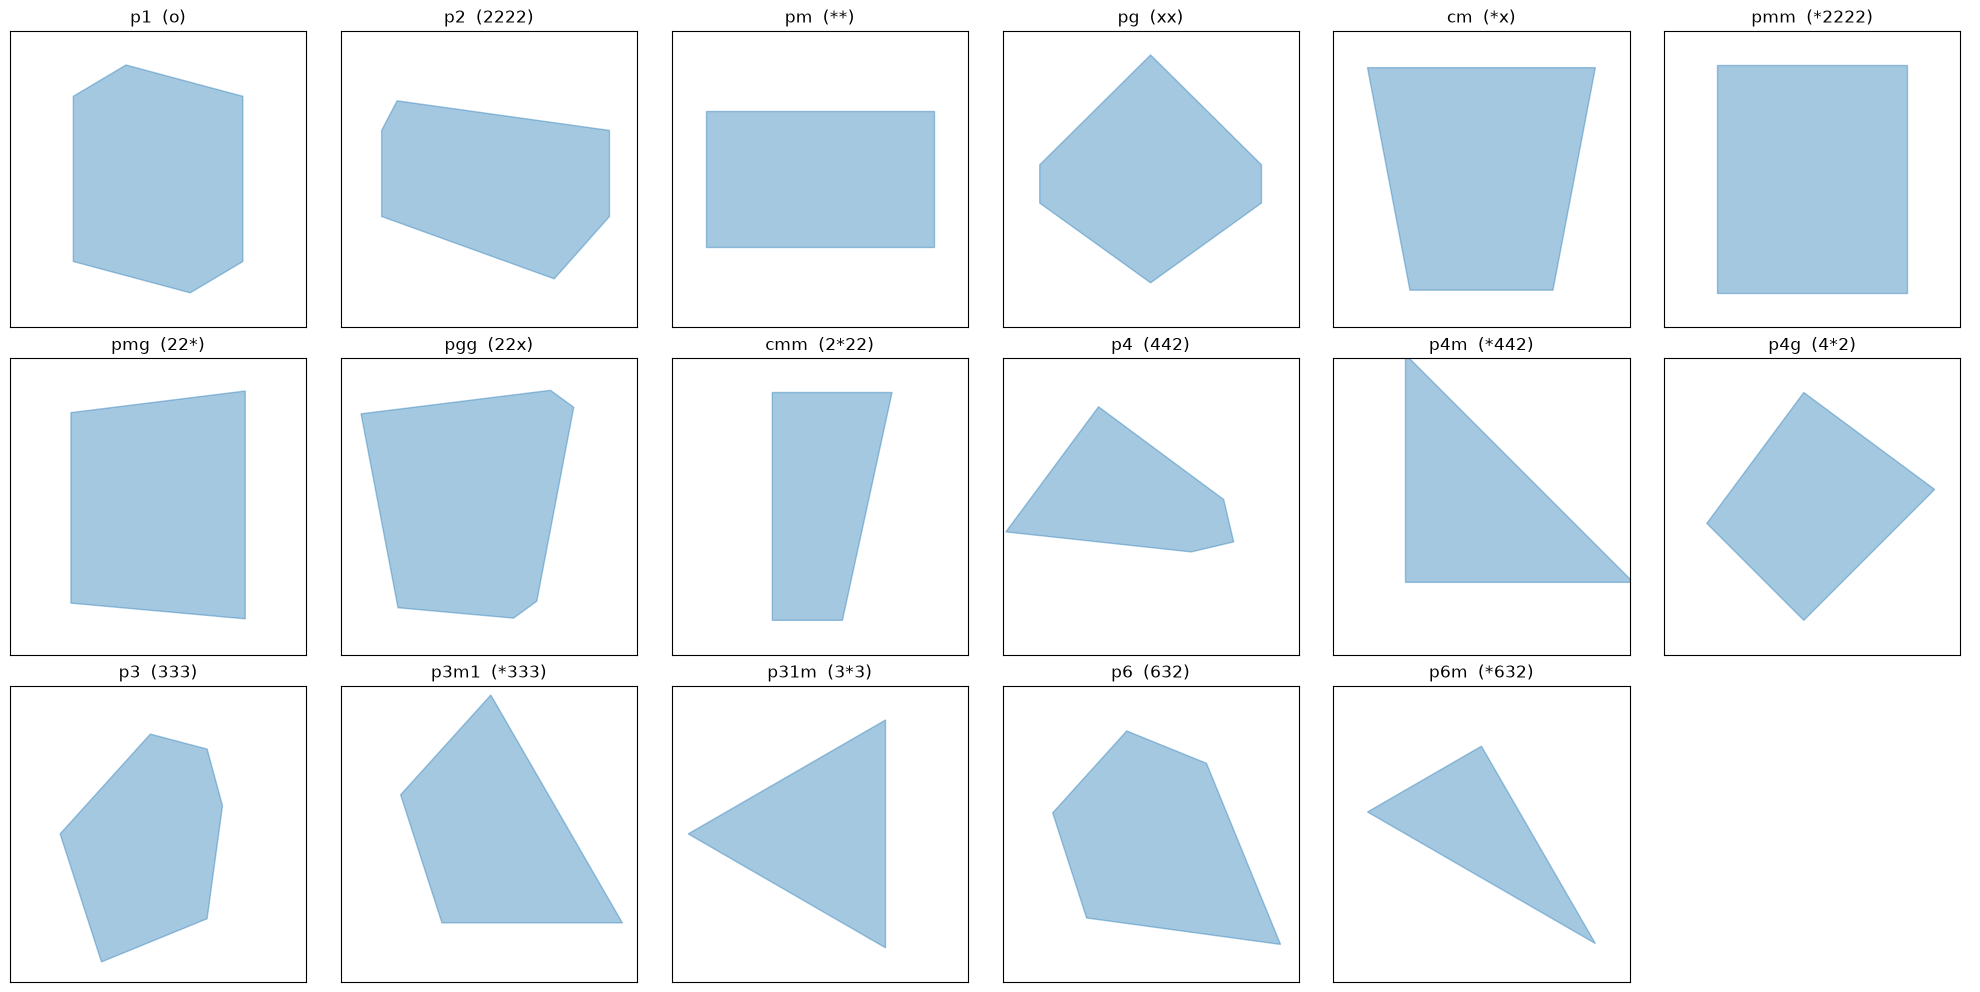

In [8]:
fig, axes = plt.subplots(3, 6, figsize=(20, 10))
for ax, symbol in zip(axes.flat, GROUP_SYMBOLS):
    a1, a2 = basis_vectors(WALLPAPER_GROUPS[symbol].lattice_kind, cell_size=1.0, ratio=1.2, angle_deg=75.0)
    poly = dirichlet_domain(symbol, a1, a2)
    ax.add_patch(MplPolygon(poly, closed=True, fc="C0", alpha=0.4, ec="C0"))
    extent = poly.max(0) - poly.min(0)
    pad = 0.15 * max(extent.max(), 1e-6)
    center = poly.mean(0)
    half = max(extent.max() / 2 + pad, 1e-6)
    ax.set_xlim(center[0] - half, center[0] + half)
    ax.set_ylim(center[1] - half, center[1] + half)
    ax.set_aspect("equal")
    ax.set_title(f"{symbol}  ({WALLPAPER_GROUPS[symbol].orbifold})")
    ax.set_xticks([])
    ax.set_yticks([])
for ax in axes.flat[len(GROUP_SYMBOLS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Verifying the domain actually tiles the plane

A Dirichlet domain is guaranteed by construction to tile the plane exactly once
under the group (that's the whole point of a Voronoi cell), but seeing it is more
convincing than being told it. Below, every copy of the `p6m` domain (one point-
group operation composed with one lattice translation) is drawn in a color keyed
to *which* of the 12 operations produced it -- no gaps, no overlaps, and you can
see the mirror/rotation structure directly in how the colors arrange themselves
around each 6-fold and 3-fold center.

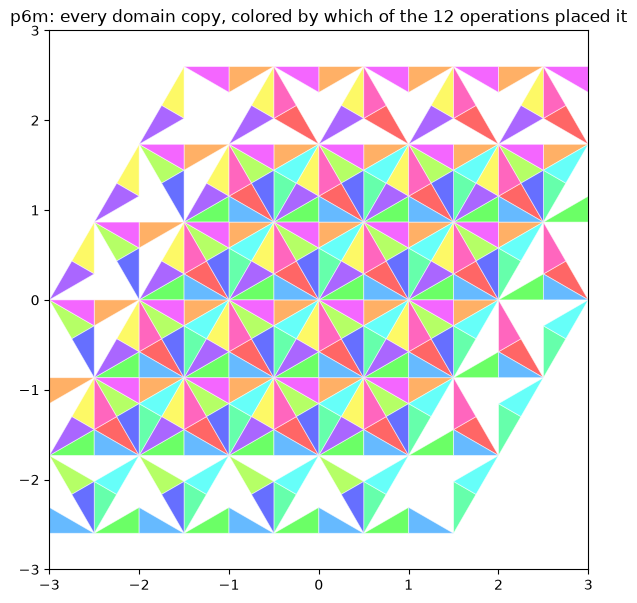

In [9]:
symbol = "p6m"
kind = WALLPAPER_GROUPS[symbol].lattice_kind
a1, a2 = basis_vectors(kind)
poly = dirichlet_domain(symbol, a1, a2)
reps = coset_representatives(symbol, a1, a2)
translations = list(lattice_translations(kind, a1, a2, range(-2, 3), range(-2, 3)))

fig, ax = plt.subplots(figsize=(7, 7))
cmap = plt.get_cmap("hsv")
for i, rep in enumerate(reps):
    color = cmap(i / len(reps))
    copy_poly = rep.apply(poly)
    for t in translations:
        ax.add_patch(MplPolygon(copy_poly + t, closed=True, fc=color, alpha=0.6, ec="white", lw=0.6))
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_aspect("equal")
ax.set_title(f"{symbol}: every domain copy, colored by which of the {len(reps)} operations placed it")
plt.show()

## 5. `FundamentalDomain`: paths, images, and world coordinates

`FundamentalDomain` ties a wallpaper group + lattice parameters to a motif -- either
free-hand vector paths, a placed raster/SVG image, or both. Its `polygon` property
is exactly the `dirichlet_domain(...)` call from above, computed for the domain's
current group and lattice parameters.

In [10]:
domain = FundamentalDomain(group="p4g", cell_size=1.2)
print("lattice kind:", domain.lattice_kind.value)
print("fundamental domain vertices (world coordinates):")
print(domain.polygon)

domain.add_path(np.array([[0.05, 0.05], [0.3, 0.1], [0.15, 0.35]]))
print("\npaths stored on the domain:", len(domain.paths))

lattice kind: square
fundamental domain vertices (world coordinates):
[[9.44650499e-01 3.44650499e-01]
 [6.00000000e-01 6.00000000e-01]
 [3.44650499e-01 2.55349501e-01]
 [6.00000000e-01 4.44089210e-16]]

paths stored on the domain: 1


Placing an **image** works through `ImagePlacement`: it stores the raw image
bytes/format/pixel-size plus a `center` (world coordinates), `scale` (world units
per pixel) and `rotation_deg`. `set_image()` loads it and auto-centers/scales it to
the domain's bounding box; `to_world_transform()` turns that into an `Affine2D`
mapping image-pixel coordinates (origin top-left, y down) to world coordinates
(origin at the lattice origin, y up).

In [11]:
buf = io.BytesIO()
PILImage.new("RGB", (120, 80), (220, 90, 40)).save(buf, format="PNG")
domain.set_image(buf.getvalue(), "swatch.png")

print("auto-placed at center:", domain.image.center)
print("auto-fit scale:", domain.image.scale, "world units / pixel")

transform = domain.image.to_world_transform()
corners_px = np.array([[0, 0], [120, 0], [120, 80], [0, 80]])
print("\nimage's 4 pixel corners, mapped into world coordinates:")
print(transform.apply(corners_px))

auto-placed at center: [0.62232525 0.3       ]
auto-fit scale: 0.004500000000000007 world units / pixel

image's 4 pixel corners, mapped into world coordinates:
[[0.35232525 0.48      ]
 [0.89232525 0.48      ]
 [0.89232525 0.12      ]
 [0.35232525 0.12      ]]


## 6. From domain to covering: `covering_transforms`, `generate_covering`, SVG export

`covering_transforms(domain, viewport_min, viewport_max)` enumerates every
`(lattice_translation, point_group_operation)` pair needed to cover a viewport --
this is the shared piece both rendering paths build on:

- `generate_covering()` applies each pair to every *vector path* on the domain and
  returns the transformed point arrays directly (handy for `svg_from_paths()` or
  any other vector export).
- the widget instead uses `covering_transforms()` directly to drive per-copy
  **canvas** `clip()` + `draw_image()` calls for a placed *image* (see part 7) --
  there's no equivalent "generate a raster covering in Python" function, because
  the browser canvas does that compositing far more efficiently than pixel-array
  code would.

392 copies of the path motif in a [-2, 2] x [-2, 2] viewport


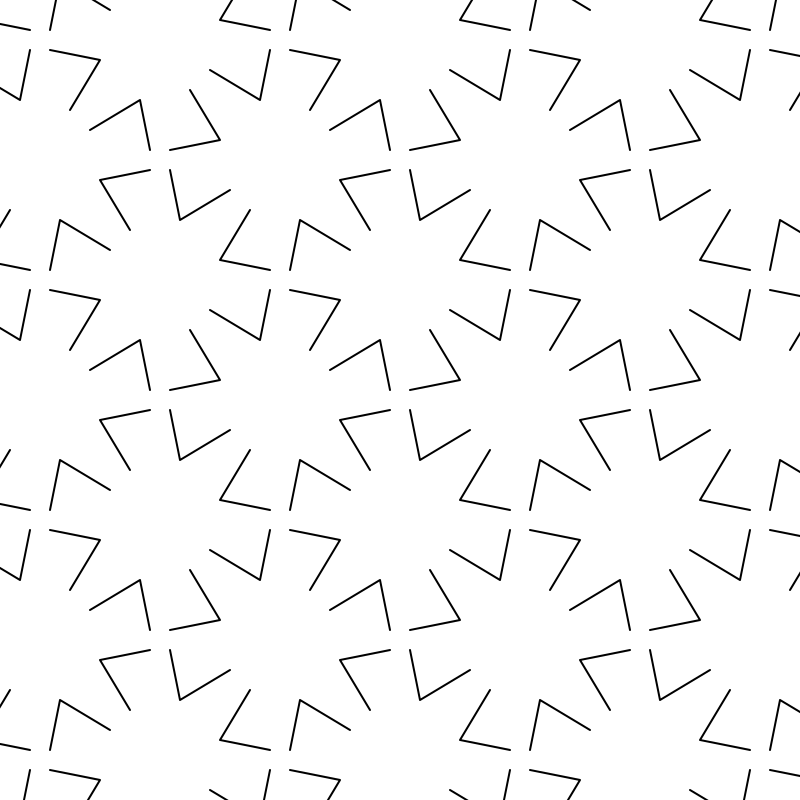

In [12]:
covering_paths = generate_covering(domain, viewport_min=(-2, -2), viewport_max=(2, 2))
print(f"{len(covering_paths)} copies of the path motif in a [-2, 2] x [-2, 2] viewport")

svg = svg_from_paths(covering_paths, viewport_min=(-2, -2), viewport_max=(2, 2))
display(SVG(svg))

In [13]:
transforms = covering_transforms(domain, viewport_min=(-2, -2), viewport_max=(2, 2))
print(f"{len(transforms)} (translation, operation) pairs")

t0, rep0 = transforms[0]
print("\nexample lattice translation:", t0)
print("example operation -- matrix:\n", rep0.matrix, "\ntranslation:", rep0.translation)

392 (translation, operation) pairs

example lattice translation: [-3.6 -3.6]
example operation -- matrix:
 [[1. 0.]
 [0. 1.]] 
translation: [0. 0.]


## 7. The interactive `TilerWidget`

Everything above is the machinery under the hood. `TilerWidget` wires it into a
live UI with two canvases side by side.

**Controls**

- **Group** dropdown -- one of the 17 wallpaper groups (label shows its orbifold
  notation, e.g. `p6m (*632)`).
- **Cell size / b:a ratio / Angle** sliders -- shape the lattice. The ratio slider
  is hidden for square/hexagonal lattices (their axis ratio is fixed by symmetry);
  the angle slider only appears for the oblique lattice (the one free-angle case).
- **Load image** -- upload a PNG or SVG. It's auto-centered on, and scaled to
  (roughly) fit, the fundamental domain's *bounding box* -- for a non-rectangular
  domain (e.g. the triangular ones in p4m/p31m/p6m) it may slightly overflow the
  polygon at first; just nudge scale/position, since the rendered covering always
  clips to the true polygon regardless.
- **Mouse: Draw / Move image** -- toggles what dragging on the left canvas does.
  "Draw" free-hand sketches a path motif; "Move image" drags the loaded image's
  position (only enabled once an image is loaded).
- **Img scale / Img rotate** sliders -- scale (log-scaled, so it feels even
  zooming in vs. out) and rotate the placed image about its own center.
- **Undo stroke / Clear strokes** -- undo or remove the free-hand paths.
- **Remove image** -- clears the loaded image.

**The two canvases**

- *Left ("Fundamental domain")*: the blue outline is the true Dirichlet domain
  polygon from parts 3-4 above (not the parallelogram cell). The image/paths are
  drawn *clipped to it* -- exactly what will appear in one copy of the covering.
- *Right ("Covering of the plane")*: for every `(translation, operation)` pair from
  `covering_transforms()`, the canvas is `save()`-d, its transform set to
  `view . translation . operation`, the domain polygon is traced and `clip()`-ped,
  the image is `draw_image()`-n (with its own placement transform composed on top),
  and the canvas is `restore()`-d. Clipping to the *true* fundamental domain rather
  than the cell is what makes image edges tile seamlessly across the group's
  mirror/rotation lines, not just across plain translations.

**Performance note**: a full covering redraw can issue thousands of draw calls (up
to 1000+ copies for the busiest groups). ipycanvas sends one message per draw call
by default, which is enough to hit Jupyter's IOPub rate limit -- so the widget
batches every canvas's draws into one message with `ipycanvas.hold_canvas()`, and
while you're dragging the image it only live-redraws the cheap left canvas,
deferring the expensive right-canvas redraw to mouse-up (same story for the
sliders, via `continuous_update=False`).

Try it:

In [14]:
from tiler import TilerWidget

TilerWidget(group="p6m")

TilerWidget(children=(VBox(children=(Dropdown(description='Group:', index=16, options=(('p1  (o)', 'p1'), ('p2…